In [1]:
from datetime import datetime
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import skewnorm, skew, norm

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

from scipy.signal import butter, filtfilt, savgol_filter

In [2]:
# df = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df["date"] = pd.to_datetime(df["date"])
df = df.set_index('date')
df.index = df.index.floor("1min")

In [3]:
df

,temp
date,
2026-11-10 15:43:00,18.38
2026-11-10 15:44:00,18.45
2026-11-10 15:45:00,18.50
2026-11-10 15:46:00,18.47
2026-11-10 15:47:00,18.47
...,...
2026-11-12 08:00:00,18.16
2026-11-12 08:01:00,18.18
2026-11-12 08:02:00,18.13


In [4]:
df_picos = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/picos_20261110_20261112.csv", sep=",") # 1 min daten
df_picos["_time"] = pd.to_datetime(df_picos["_time"], format="mixed")
df_picos = df_picos[["_time", "_value", "DEVICE_ID"]]
df_picos.columns = ['date', 'temp', 'id']
df_picos = df_picos.set_index('date')
df_picos.index = df_picos.index.tz_localize(None)

In [5]:
df_picos

,temp,id
date,,
2026-11-10 15:29:12.185645916,23.27,pico_2
2026-11-10 15:30:12.157509173,19.47,pico_2
2026-11-10 15:31:12.162231005,19.73,pico_2
2026-11-10 15:32:12.190244584,20.21,pico_2
2026-11-10 15:33:12.226758630,20.65,pico_2
...,...,...
2026-11-12 10:16:49.660737062,21.56,pico_7
2026-11-12 10:17:49.685786578,21.91,pico_7
2026-11-12 10:18:49.712780284,21.97,pico_7


In [6]:
# 1 min daten
df_pico2 = df_picos[df_picos["id"] == "pico_2"]
pos = df_pico2.index.get_indexer(df.index, method="nearest")
df_pico2 = df_pico2.iloc[pos].drop(columns=["id"])
df_pico2.index = df.index

df_pico3 = df_picos[df_picos["id"] == "pico_3"]
pos = df_pico3.index.get_indexer(df.index, method="nearest")
df_pico3 = df_pico3.iloc[pos].drop(columns=["id"])
df_pico3.index = df.index

df_pico4 = df_picos[df_picos["id"] == "pico_4"]
pos = df_pico4.index.get_indexer(df.index, method="nearest")
df_pico4 = df_pico4.iloc[pos].drop(columns=["id"])
df_pico4.index = df.index

df_pico5 = df_picos[df_picos["id"] == "pico_5"]
pos = df_pico5.index.get_indexer(df.index, method="nearest")
df_pico5 = df_pico5.iloc[pos].drop(columns=["id"])
df_pico5.index = df.index

df_pico6 = df_picos[df_picos["id"] == "pico_6"]
pos = df_pico6.index.get_indexer(df.index, method="nearest")
df_pico6 = df_pico6.iloc[pos].drop(columns=["id"])
df_pico6.index = df.index

df_pico7 = df_picos[df_picos["id"] == "pico_7"]
pos = df_pico7.index.get_indexer(df.index, method="nearest")
df_pico7 = df_pico7.iloc[pos].drop(columns=["id"])
df_pico7.index = df.index

In [7]:
picos_dfs = [df_pico2, df_pico3, df_pico4, df_pico5, df_pico6, df_pico7]

In [8]:
picos_dfs_names = ["Pico_2", "Pico_3", "Pico_4", "Pico_5", "Pico_6", "Pico_7"]

In [9]:
dfs = [df_pico2, df_pico3, df_pico4, df_pico5, df_pico6, df_pico7, df]

In [10]:
dfs_names = ["Pico_2", "Pico_3", "Pico_4", "Pico_5", "Pico_6", "Pico_7", "Senseca"]

In [11]:
# 1 min data
summary = ergebnis = pd.concat(dfs, axis=1)
summary.columns = dfs_names

In [12]:
summary

,Pico_2,Pico_3,Pico_4,Pico_5,Pico_6,Pico_7,Senseca
date,,,,,,,
2026-11-10 15:43:00,21.95,21.40,23.18,22.30,20.86,20.82,18.38
2026-11-10 15:44:00,21.97,21.41,23.16,22.60,20.88,20.85,18.45
2026-11-10 15:45:00,21.98,21.41,23.12,22.30,20.91,20.83,18.50
2026-11-10 15:46:00,21.92,21.39,23.11,22.11,20.82,20.82,18.47
2026-11-10 15:47:00,22.60,21.42,23.16,22.12,20.90,20.91,18.47
...,...,...,...,...,...,...,...
2026-11-12 08:00:00,22.90,21.27,23.42,22.19,20.90,21.40,18.16
2026-11-12 08:01:00,22.60,21.17,23.32,22.14,20.88,20.94,18.18
2026-11-12 08:02:00,22.70,21.70,23.18,22.12,20.87,20.87,18.13


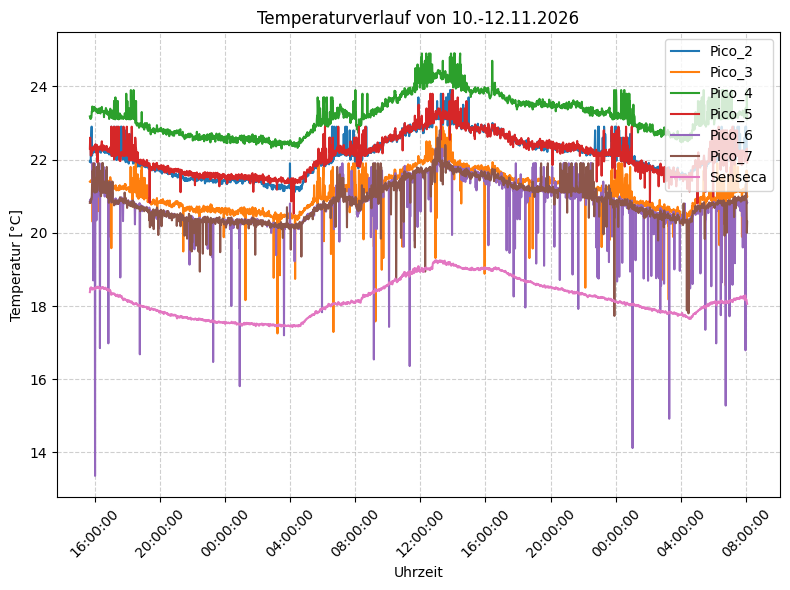

In [13]:
# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(summary.index, summary)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(summary.columns, loc='upper right')

plt.show()

In [14]:
summary_sorted = summary.sort_values(by="Senseca", ascending=True)

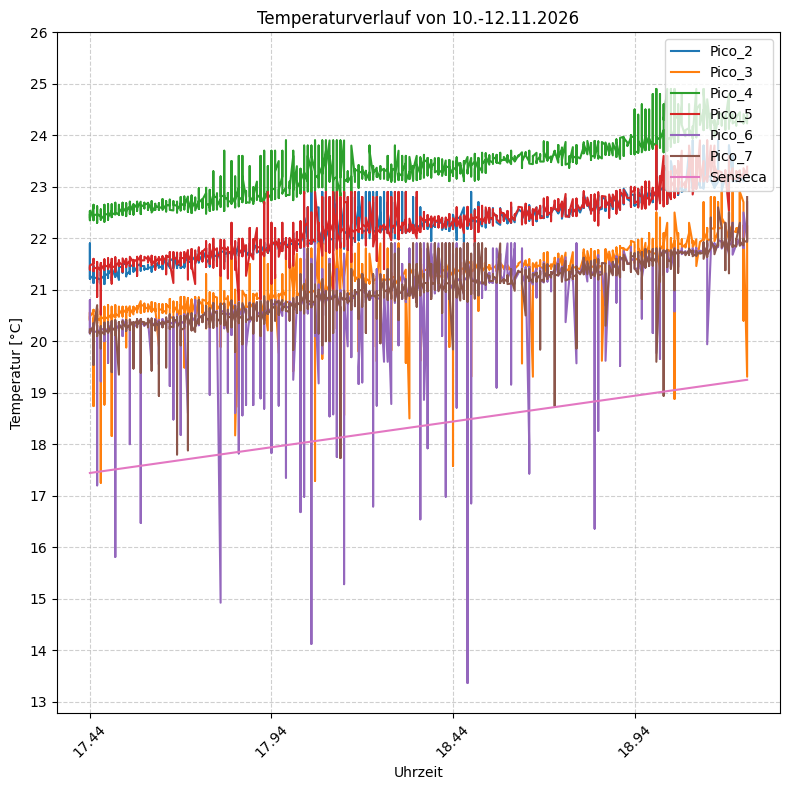

In [15]:
# Diagramm zeichnen
plt.figure(figsize=(8, 8))
plt.plot(summary_sorted["Senseca"].values, summary_sorted)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.yticks(np.arange(13, 27, 1))
plt.xticks(np.arange(summary_sorted["Senseca"].min(), summary_sorted["Senseca"].max(), 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(summary.columns, loc='upper right')

plt.show()

In [16]:
test = summary_sorted[["Pico_4", "Senseca"]]

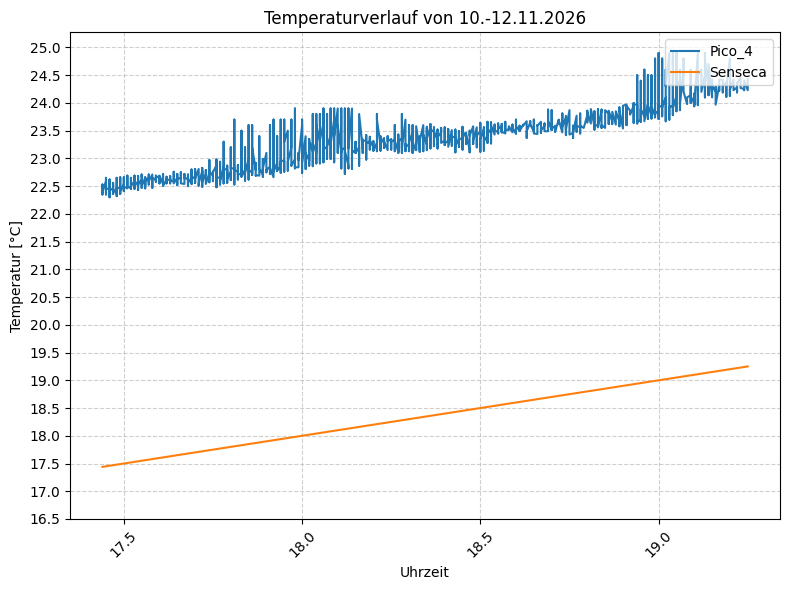

In [17]:
# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(test["Senseca"].values, test)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.yticks(np.arange(16.5, 25.5, 0.5))
plt.xticks(np.arange(17.5, 19.5, 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(test.columns, loc='upper right')

plt.show()

In [18]:
x = test["Pico_4"].to_numpy().reshape(-1, 1) # train[["temp_sensor"]].to_numpy()
y = test["Senseca"].to_numpy().reshape(-1, 1) # train["temp_ref"].to_numpy()

# 4. Univariate lineare Regression (OLS) fitten
model = LinearRegression()
model.fit(x, y)

alpha_0 = model.intercept_
alpha_1 = model.coef_[0]
print(f"Kalibrierformel: T_kal = {alpha_0} + {alpha_1} * T_sensor")

Kalibrierformel: T_kal = [-2.26130228] + [0.88126319] * T_sensor


In [19]:
x = summary["Pico_4"].to_numpy().reshape(-1, 1) # train[["temp_sensor"]].to_numpy()
y = summary["Senseca"].to_numpy().reshape(-1, 1) # train["temp_ref"].to_numpy()

# 4. Univariate lineare Regression (OLS) fitten
model = LinearRegression()
model.fit(x, y)

alpha_0 = model.intercept_
alpha_1 = model.coef_[0]
print(f"Kalibrierformel: T_kal = {alpha_0} + {alpha_1} * T_sensor")

Kalibrierformel: T_kal = [-2.26130228] + [0.88126319] * T_sensor


In [20]:
test["Pico_4_cal_lin"] = test["Pico_4"] * alpha_1 + alpha_0

/tmp/ipykernel_889795/105761653.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test["Pico_4_cal_lin"] = test["Pico_4"] * alpha_1 + alpha_0


In [21]:
test

,Pico_4,Senseca,Pico_4_cal_lin
date,,,
2026-11-11 04:09:00,22.45,17.44,17.523056
2026-11-11 04:11:00,22.45,17.44,17.523056
2026-11-11 03:28:00,22.43,17.44,17.505431
2026-11-11 04:01:00,22.53,17.44,17.593557
2026-11-11 04:00:00,22.50,17.44,17.567120
...,...,...,...
2026-11-11 13:14:00,24.33,19.24,19.179831
2026-11-11 13:11:00,24.41,19.24,19.250332
2026-11-11 12:56:00,24.23,19.25,19.091705


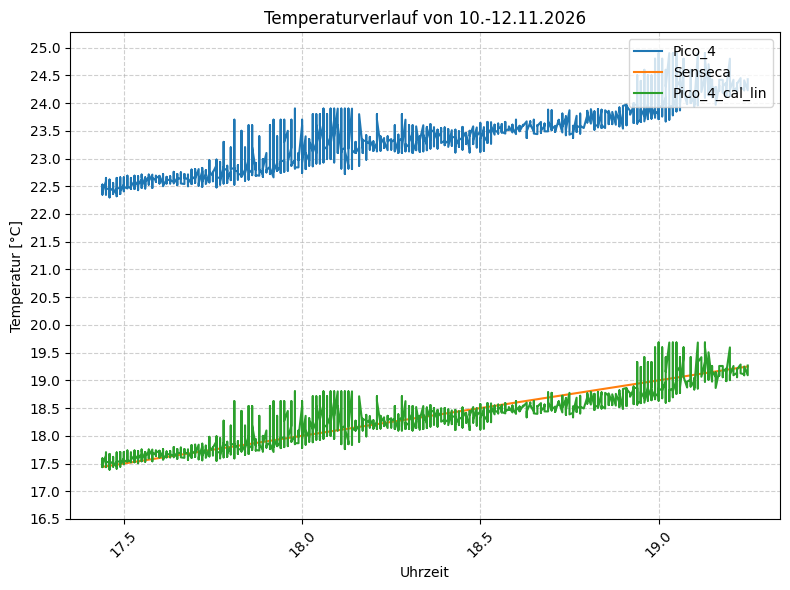

In [22]:
# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(test["Senseca"].values, test)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.yticks(np.arange(16.5, 25.5, 0.5))
plt.xticks(np.arange(17.5, 19.5, 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(test.columns, loc='upper right')

plt.show()

In [23]:
x = test["Pico_4"].to_numpy().reshape(-1, 1)
y = test["Senseca"].to_numpy().reshape(-1, 1)

grad = 2  # z. B. 2 für quadratisch, 3 für kubisch

# Polynomiale Features + lineare Regression als Pipeline
poly_model = make_pipeline(
    PolynomialFeatures(degree=grad, include_bias=False),
    LinearRegression(),
)
poly_model.fit(x, y)

# Koeffizienten und Intercept auslesen
lin_reg = poly_model.named_steps["linearregression"]
alpha_0 = lin_reg.intercept_[0]
coefs = lin_reg.coef_[0]  # [a_1, a_2, ..., a_grad]

formel_teile = [f"{coefs[i]:.6g} * T_sensor^{i + 1}" for i in range(len(coefs))]
print(f"Kalibrierformel (Grad {grad}): T_kal = {alpha_0:.6g} + " + " + ".join(formel_teile))

Kalibrierformel (Grad 2): T_kal = -74.2246 + 7.05201 * T_sensor^1 + -0.132211 * T_sensor^2


In [24]:
coefs

array([ 7.05200886, -0.13221064])

In [25]:
test["Pico_4_cal_poly_2"] = test["Pico_4"]**2 * coefs[1] + test["Pico_4"] * coefs[0] + alpha_0

/tmp/ipykernel_889795/16398194.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test["Pico_4_cal_poly_2"] = test["Pico_4"]**2 * coefs[1] + test["Pico_4"] * coefs[0] + alpha_0


In [26]:
test


,Pico_4,Senseca,Pico_4_cal_lin,Pico_4_cal_poly_2
date,,,,
2026-11-11 04:09:00,22.45,17.44,17.523056,17.458497
2026-11-11 04:11:00,22.45,17.44,17.523056,17.458497
2026-11-11 03:28:00,22.43,17.44,17.505431,17.436130
2026-11-11 04:01:00,22.53,17.44,17.593557,17.546911
2026-11-11 04:00:00,22.50,17.44,17.567120,17.513954
...,...,...,...,...
2026-11-11 13:14:00,24.33,19.24,19.179831,19.088824
2026-11-11 13:11:00,24.41,19.24,19.250332,19.137469
2026-11-11 12:56:00,24.23,19.25,19.091705,19.025638


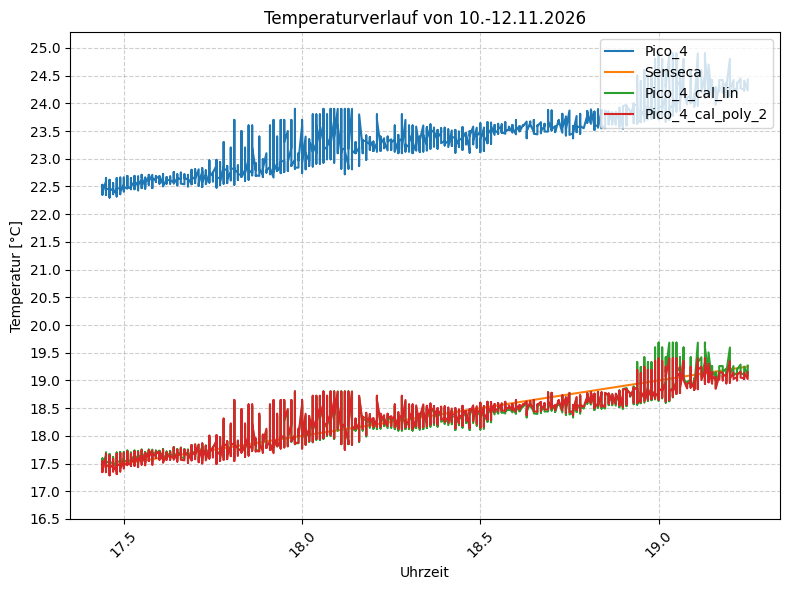

In [27]:
# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(test["Senseca"].values, test)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.yticks(np.arange(16.5, 25.5, 0.5))
plt.xticks(np.arange(17.5, 19.5, 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(test.columns, loc='upper right')

plt.show()

In [28]:
x = test["Pico_4"].to_numpy().reshape(-1, 1)
y = test["Senseca"].to_numpy().reshape(-1, 1)

grad = 3  # z. B. 2 für quadratisch, 3 für kubisch

# Polynomiale Features + lineare Regression als Pipeline
poly_model = make_pipeline(
    PolynomialFeatures(degree=grad, include_bias=False),
    LinearRegression(),
)
poly_model.fit(x, y)

# Koeffizienten und Intercept auslesen
lin_reg = poly_model.named_steps["linearregression"]
alpha_0 = lin_reg.intercept_[0]
coefs = lin_reg.coef_[0]  # [a_1, a_2, ..., a_grad]

formel_teile = [f"{coefs[i]:.6g} * T_sensor^{i + 1}" for i in range(len(coefs))]
print(f"Kalibrierformel (Grad {grad}): T_kal = {alpha_0:.6g} + " + " + ".join(formel_teile))


Kalibrierformel (Grad 3): T_kal = -19.4859 + 0.00723972 * T_sensor^1 + 0.169874 * T_sensor^2 + -0.00431598 * T_sensor^3


In [29]:
coefs


array([ 0.00723972,  0.16987431, -0.00431598])

In [30]:
test["Pico_4_cal_poly_3"] = test["Pico_4"]**3 * coefs[2] + test["Pico_4"]**2 * coefs[1] + test["Pico_4"] * coefs[0] + alpha_0


/tmp/ipykernel_889795/2679786051.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test["Pico_4_cal_poly_3"] = test["Pico_4"]**3 * coefs[2] + test["Pico_4"]**2 * coefs[1] + test["Pico_4"] * coefs[0] + alpha_0


In [31]:
test


,Pico_4,Senseca,Pico_4_cal_lin,Pico_4_cal_poly_2,Pico_4_cal_poly_3
date,,,,,
2026-11-11 04:09:00,22.45,17.44,17.523056,17.458497,17.458961
2026-11-11 04:11:00,22.45,17.44,17.523056,17.458497,17.458961
2026-11-11 03:28:00,22.43,17.44,17.505431,17.436130,17.436737
2026-11-11 04:01:00,22.53,17.44,17.593557,17.546911,17.546890
2026-11-11 04:00:00,22.50,17.44,17.567120,17.513954,17.514099
...,...,...,...,...,...
2026-11-11 13:14:00,24.33,19.24,19.179831,19.088824,19.087843
2026-11-11 13:11:00,24.41,19.24,19.250332,19.137469,19.135616
2026-11-11 12:56:00,24.23,19.25,19.091705,19.025638,19.025516


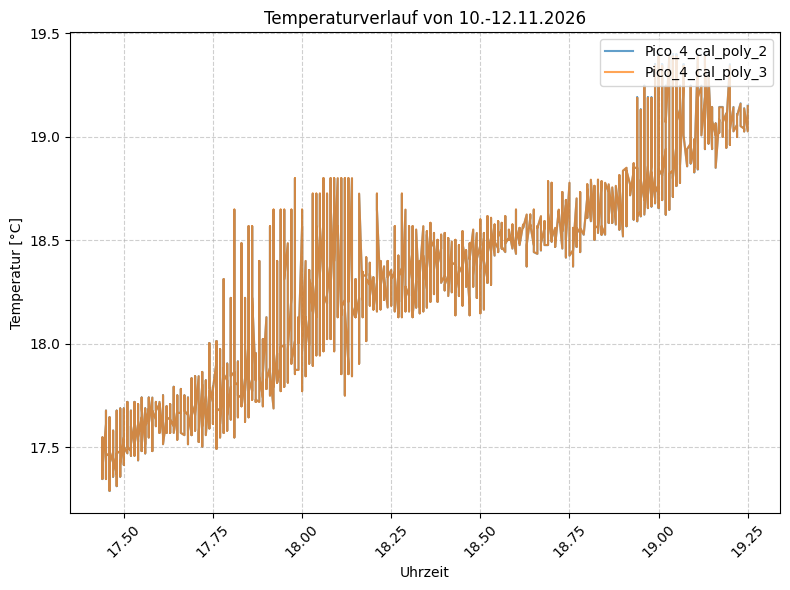

In [32]:

# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(test["Senseca"].values, test[["Pico_4_cal_poly_2", "Pico_4_cal_poly_3"]], label=test[["Pico_4_cal_poly_2", "Pico_4_cal_poly_3"]].columns, alpha=0.7)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
# plt.yticks(np.arange(16.5, 25.5, 0.5))
# plt.xticks(np.arange(17.5, 19.5, 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()

In [33]:
# Werte glätten

In [34]:
savgol = pd.Series(
    savgol_filter(summary_sorted["Pico_2"].to_numpy(), window_length=61, polyorder=2),
    index=summary_sorted["Pico_2"].index,
)

In [35]:
ema = summary_sorted["Pico_2"].ewm(span=60, adjust=False).mean()

In [36]:
med_centered = summary_sorted["Pico_2"].rolling(window=60, center=True, min_periods=1).median()

In [37]:
x = summary_sorted["Senseca"]#.groupby(np.arange(len(summary_sorted)) // 10).mean()
# y = summary_sorted["Pico_2"]#.groupby(np.arange(len(summary_sorted)) // 10).mean()
ys = [summary_sorted["Pico_2"], savgol, ema, med_centered]
trend_names = ["original", "savgol", "ema", "med_centered"]

def trendLine(x, y):
    # Geradensteigung m und Achsenabschnitt b berechnen (Grad 1)
    m, b = np.polyfit(x, y, deg=1)
    y_trend = np.polyval([m, b], x)

    # a, b, c = np.polyfit(x, y, deg=2)
    # y_trend = np.polyval([a, b, c], x)

    # Bestimmtheitsmaß R^2 wie in Excel berechnen

    # Bezogen auf die original Daten
    # ss_res = np.sum((summary_sorted["Pico_2"] - y_trend) ** 2)
    # ss_tot = np.sum((summary_sorted["Pico_2"] - np.mean(summary_sorted["Pico_2"])) ** 2)

    # Bezogen auf die jeweilige Glättung
    ss_res = np.sum((y - y_trend) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return y_trend, r2

trends = []
r2s = []

for y in ys:
    y_trend, r2 = trendLine(x, y)
    trends.append(y_trend)
    r2s.append(r2)

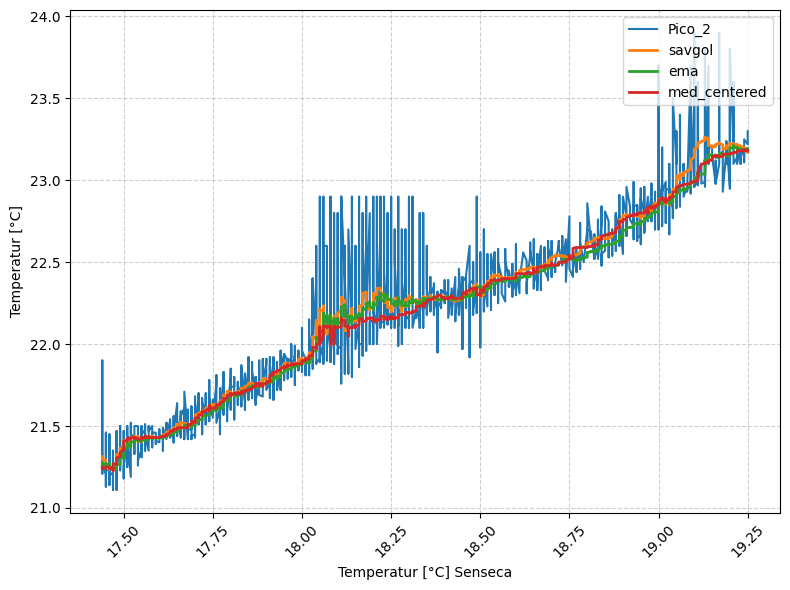

In [38]:
# Diagramm zeichnen

plt.figure(figsize=(8, 6))#, dpi=200)
plt.plot(x, summary_sorted["Pico_2"], label="Pico_2")

# for trend, r2, trend_name in zip(trends, r2s, trend_names):
#     plt.plot(x, trend, linewidth=2, label=f"Method: {trend_name}, R² = {r2:.4f}")#f"Trend: y = {m:.4g}x + {b:.4g} (R² = {r2:.4f})")


plt.plot(x, savgol, linewidth=2, label="savgol")
plt.plot(x, ema, linewidth=2, label="ema")
plt.plot(x, med_centered, linewidth=2, label="med_centered")


# plt.plot(summary_sorted["Senseca"].values, y_trend, color="red", linewidth=2, label=f"Trend: y = {a:.4g}x^2 + {b:.4g}x + {c:.4g} (R² = {r2:.4f})")
# Achsen und Layout formatieren
plt.title("")
plt.xlabel("Temperatur [°C] Senseca")
plt.ylabel("Temperatur [°C]")
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
# plt.yticks(np.arange(16.5, 25.5, 0.5))
# plt.xticks(np.arange(17.5, 19.5, 0.5))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()

In [39]:
np.std(ys[1], ddof=1)

0.5176700199569158

In [40]:
def calculate_rmssd(data):
    data = np.asarray(data)
    differences = np.diff(data)
    return np.sqrt(np.mean(differences**2))

In [41]:
rmssd = calculate_rmssd(x)

print(f"RMSSD: {rmssd:.4f} °C")

RMSSD: 0.0027 °C


In [42]:
x = summary_sorted["Pico_2"].copy()
ys = [summary_sorted["Pico_2"], savgol, ema, med_centered]

print("mae, rmse, std, rmssd")
for y in ys:
    mae = mean_absolute_error(x, y)
    rmse = root_mean_squared_error(x, y)
    std = np.std(y, ddof=1)
    rmssd = calculate_rmssd(y)
    print(round(mae, 2), round(rmse, 2), round(std, 2), round(rmssd, 2))

mae, rmse, std, rmssd
0.0 0.0 0.54 0.21
0.1 0.15 0.52 0.01
0.09 0.15 0.51 0.01
0.09 0.16 0.51 0.01


In [43]:
def hampel_filter(series, window_size=60, n_sigmas=6):

    rolling_median = series.rolling(
        window=2 * window_size + 1,
        center=True,
        min_periods=1
    ).median()

    abs_deviation = (series - rolling_median).abs()

    rolling_mad = abs_deviation.rolling(
        window=2 * window_size + 1,
        center=True,
        min_periods=1
    ).median()

    threshold = n_sigmas * 1.4826 * rolling_mad

    outliers = abs_deviation > threshold

    filtered = series.copy()
    filtered[outliers] = rolling_median[outliers]

    return filtered, outliers

In [44]:
df["temperature_hampel"], df["outlier"] = hampel_filter(
    x,
    window_size=5,
    n_sigmas=3
)

In [45]:
df

,temp,temperature_hampel,outlier
date,,,
2026-11-10 15:43:00,18.38,22.26,True
2026-11-10 15:44:00,18.45,22.33,True
2026-11-10 15:45:00,18.50,22.30,True
2026-11-10 15:46:00,18.47,22.33,True
2026-11-10 15:47:00,18.47,22.60,False
...,...,...,...
2026-11-12 08:00:00,18.16,22.90,False
2026-11-12 08:01:00,18.18,22.17,True
2026-11-12 08:02:00,18.13,22.70,False


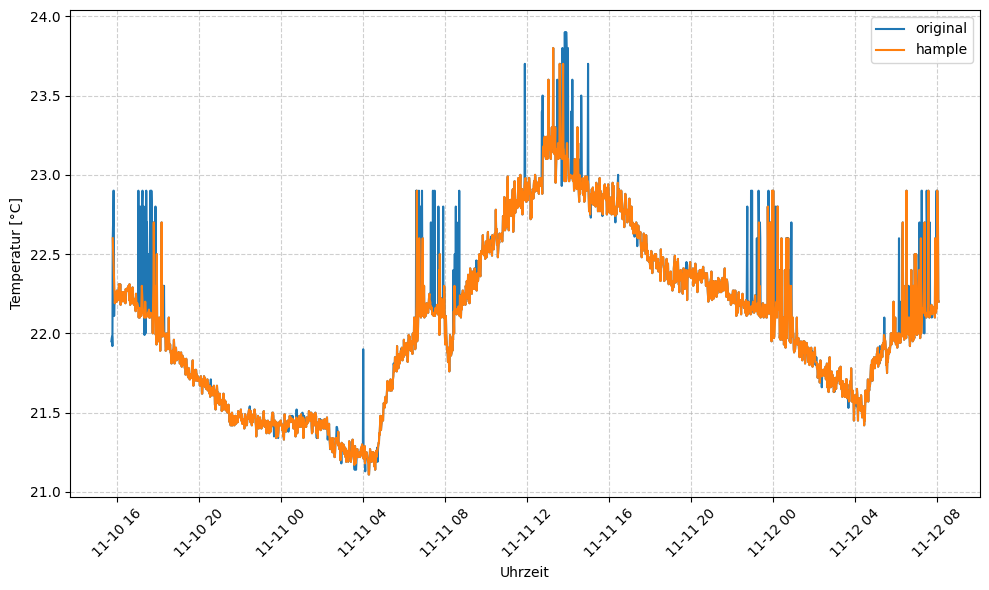

In [46]:
# Diagramm zeichnen
plt.figure(figsize=(10, 6))
plt.plot(summary["Pico_2"].index, summary["Pico_2"], label="original")
plt.plot(df["temperature_hampel"][df["outlier"] == False].index, df["temperature_hampel"][df["outlier"] == False], label="hample")

# Achsen und Layout formatieren
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()

In [59]:
def calibration(data, ref_data):
    med_centered = data.rolling(window=60, center=True, min_periods=1).median()

    x = med_centered.to_numpy().reshape(-1, 1)
    y = ref_data.to_numpy().reshape(-1, 1)

    model = LinearRegression()
    model.fit(x, y)

    alpha_0 = model.intercept_
    alpha_1 = model.coef_[0]
    
    print(f"Kalibrierformel: T_kal = {alpha_0} + {alpha_1} * T_sensor")

    df = med_centered  * alpha_1 + alpha_0

    return df

In [60]:
summary

,Pico_2,Pico_3,Pico_4,Pico_5,Pico_6,Pico_7,Senseca
date,,,,,,,
2026-11-10 15:43:00,21.95,21.40,23.18,22.30,20.86,20.82,18.38
2026-11-10 15:44:00,21.97,21.41,23.16,22.60,20.88,20.85,18.45
2026-11-10 15:45:00,21.98,21.41,23.12,22.30,20.91,20.83,18.50
2026-11-10 15:46:00,21.92,21.39,23.11,22.11,20.82,20.82,18.47
2026-11-10 15:47:00,22.60,21.42,23.16,22.12,20.90,20.91,18.47
...,...,...,...,...,...,...,...
2026-11-12 08:00:00,22.90,21.27,23.42,22.19,20.90,21.40,18.16
2026-11-12 08:01:00,22.60,21.17,23.32,22.14,20.88,20.94,18.18
2026-11-12 08:02:00,22.70,21.70,23.18,22.12,20.87,20.87,18.13


In [61]:
pico2_cal = calibration(summary["Pico_2"], summary["Senseca"])

Kalibrierformel: T_kal = [-3.45703253] + [0.98062172] * T_sensor


In [62]:
pico2_cal

date
2026-11-10 15:43:00    18.356898
2026-11-10 15:44:00    18.351995
2026-11-10 15:45:00    18.356898
2026-11-10 15:46:00    18.361801
2026-11-10 15:47:00    18.361801
                         ...    
2026-11-12 08:00:00    18.263739
2026-11-12 08:01:00    18.263739
2026-11-12 08:02:00    18.263739
2026-11-12 08:03:00    18.268642
2026-11-12 08:04:00    18.263739
Name: Pico_2, Length: 2422, dtype: float64

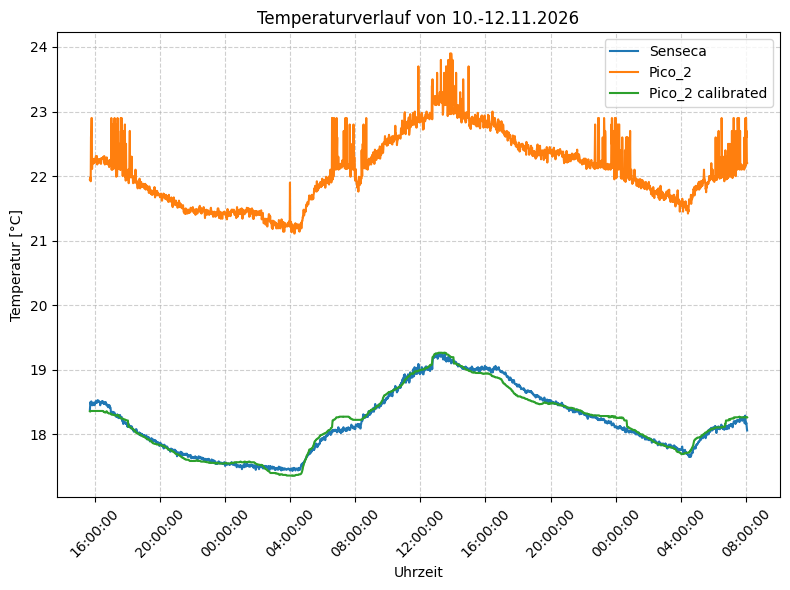

In [63]:
# Diagramm zeichnen
plt.figure(figsize=(8, 6))
plt.plot(summary.index, summary["Senseca"], label="Senseca")
plt.plot(summary.index, summary["Pico_2"], label="Pico_2")
plt.plot(summary.index, pico2_cal, label="Pico_2 calibrated")

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()